In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("supermarket_sales.csv")
df.head()

,invoice_id,branch,city,customer_type,gender_customer,product_line,unit_cost,quantity,5pct_markup,revenue,date,time,payment_method,cogs,gm_pct,gross_income,rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,01/05/19,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,03/08/19,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,03/03/19,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,02/08/19,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   invoice_id       1000 non-null   str    
 1   branch           1000 non-null   str    
 2   city             1000 non-null   str    
 3   customer_type    1000 non-null   str    
 4   gender_customer  1000 non-null   str    
 5   product_line     1000 non-null   str    
 6   unit_cost        1000 non-null   float64
 7   quantity         1000 non-null   int64  
 8   5pct_markup      1000 non-null   float64
 9   revenue          1000 non-null   float64
 10  date             1000 non-null   str    
 11  time             1000 non-null   str    
 12  payment_method   1000 non-null   str    
 13  cogs             1000 non-null   float64
 14  gm_pct           1000 non-null   float64
 15  gross_income     1000 non-null   float64
 16  rating           1000 non-null   float64
dtypes: float64(7), int64(1), s

In [3]:
df.isnull().sum()

invoice_id         0
branch             0
city               0
customer_type      0
gender_customer    0
product_line       0
unit_cost          0
quantity           0
5pct_markup        0
revenue            0
date               0
time               0
payment_method     0
cogs               0
gm_pct             0
gross_income       0
rating             0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.describe()

,unit_cost,quantity,5pct_markup,revenue,cogs,gm_pct,gross_income,rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,0.000000,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905,49.650000,10.00000


In [6]:
df.groupby("product_line")["revenue"].sum()

product_line
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Food and beverages        56144.8440
Health and beauty         49193.7390
Home and lifestyle        53861.9130
Sports and travel         55122.8265
Name: revenue, dtype: float64

In [7]:
df.groupby("product_line")["revenue"].sum().sort_values(ascending=False)

product_line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: revenue, dtype: float64

In [8]:
df.groupby("branch")["revenue"].sum()

branch
A    106200.3705
B    106197.6720
C    110568.7065
Name: revenue, dtype: float64

In [9]:
df["payment_method"].value_counts()

payment_method
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

<Axes: xlabel='product_line'>

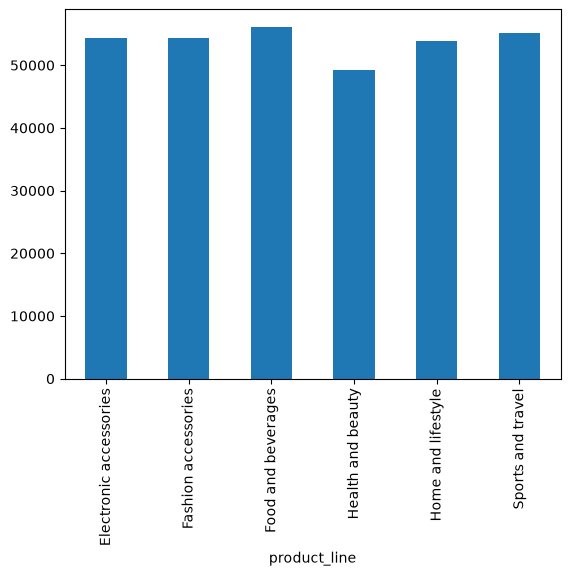

In [10]:
df.groupby("product_line")["revenue"].sum().plot(kind="bar")

# supermarket Sales Analysis
**Data check: ** 1000 rows, No any duplicate  , no any missing values.

**Finding:**
-Food and beverages generate the highest revenue.
Health and beauty generate the lowest revenue.
Branch C had the highest total revenue.
Revenue was spread was spread fairly evenly across the product lines

month
2019-01    116291.868
2019-02     97219.374
2019-03    109455.507
Freq: M, Name: revenue, dtype: float64


C:\Users\ABDUL\AppData\Local\Temp\ipykernel_16240\1812221046.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['date'])


<Axes: xlabel='month'>

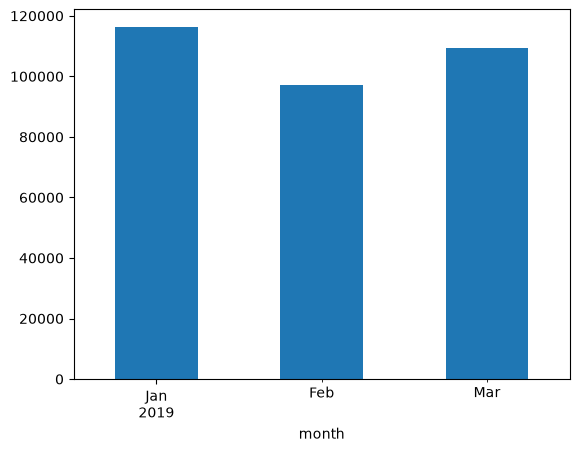

In [11]:
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.to_period('M')

monthly_sales = df.groupby('month')['revenue'].sum()
print(monthly_sales)

monthly_sales.plot(kind='bar')

In [12]:
df.columns

Index(['invoice_id', 'branch', 'city', 'customer_type', 'gender_customer',
       'product_line', 'unit_cost', 'quantity', '5pct_markup', 'revenue',
       'date', 'time', 'payment_method', 'cogs', 'gm_pct', 'gross_income',
       'rating', 'month'],
      dtype='str')

**Monthly Trend:**
-January had the highest revenue (116,291.87).
-February had the lowest revenue (97,219.37), about 16.4% lower than January.
-March recovered to 109,455.51
-The data cover only 3 month (Jan-Mar 2019).

payment_method
Cash           112206.570
Credit card    100767.072
Ewallet        109993.107
Name: revenue, dtype: float64


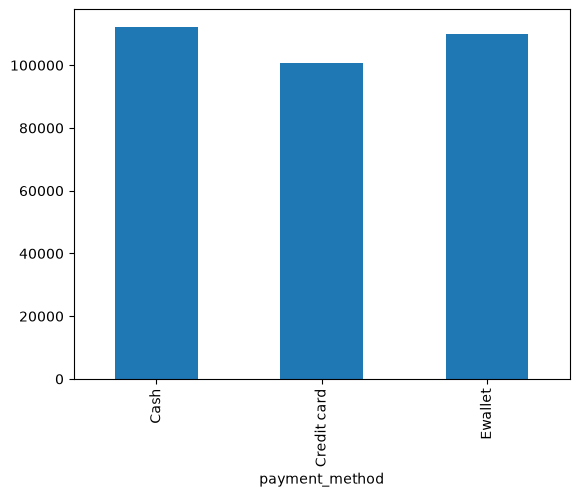

In [13]:
payment_sales = df.groupby('payment_method')['revenue'].sum()
print(payment_sales)

payment_sales.plot(kind='bar')
plt.show()

**Payment Method:**

- Cash had the highest revenue (112,206.57), about 34.7% of the total.
- Ewallet was close behind (109,993.11), about 34.1%.
- Credit card had the lowest revenue (100,767.07), about 31.2%.
- Reveune is spread fairly evenly across the three payment methods.

customer_type
Member    164223.444
Normal    158743.305
Name: revenue, dtype: float64


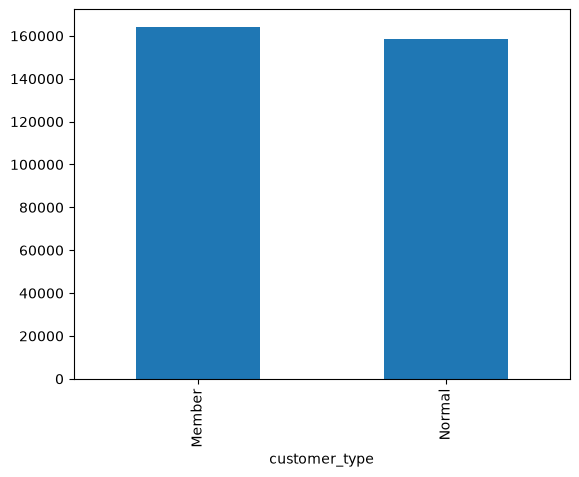

In [14]:
customer_sales = df.groupby('customer_type')['revenue'].sum()
print(customer_sales)

customer_sales.plot(kind='bar')
plt.show()

**Customer Type:**
- Members generated 164,223.44 in revenue, about 50.8% of the total.
- Normal customer generated 158,743., about 49.2%.
- Member spent about 3.5% more in total that normal customers.
- Revenue is split almost evenly between the two customer types .

gender_customer
Female    167882.925
Male      155083.824
Name: revenue, dtype: float64


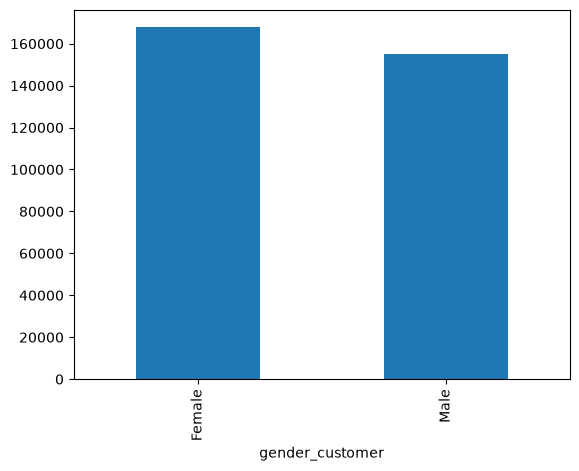

In [15]:
gender_sales = df.groupby('gender_customer')['revenue'].sum()
print(gender_sales)

gender_sales.plot(kind='bar')
plt.show()

**Gender:**
- Female customer generated 167,882.93 in revenue, about 52.0% of the total.
- Male customer generated 155,083.82 in revenue , about 48,0% of the total.
- Female customer spent about 8.3% more in total than male customers. 

6.9727
product_line
Electronic accessories    6.924706
Fashion accessories       7.029213
Food and beverages        7.113218
Health and beauty         7.003289
Home and lifestyle        6.837500
Sports and travel         6.916265
Name: rating, dtype: float64


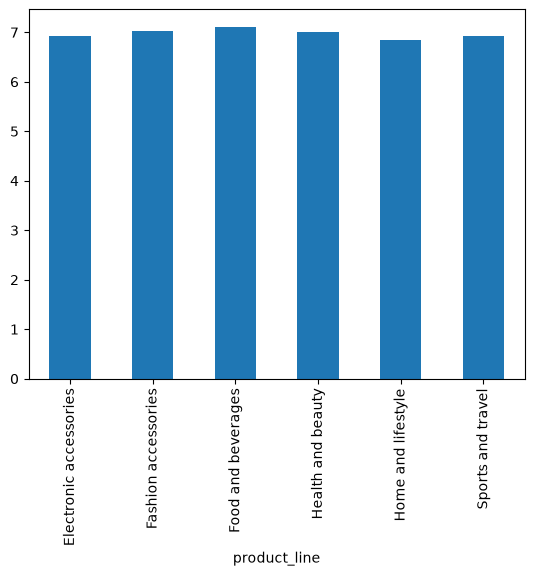

In [16]:
print(df['rating'].mean())

rating_by_product = df.groupby('product_line')['rating'].mean()
print(rating_by_product)

rating_by_product.plot(kind='bar')
plt.show()

**Customer Rating:**
- The average rating across all 1000 transactions is 6.97.
- Food and beverage had the highest average rating (7.11).
- Home and lifestyle had the lowest average rating (6.84).
- The gap between the highest and lowest is only about 0.28 (4.0%), so customer satisfactionis similar across all product lines.
- Food and beverage is both the top revenue and the best rated product line.  

hour
10    31421.4810
11    30377.3295
12    26065.8825
13    34723.2270
14    30828.3990
15    31179.5085
16    25226.3235
17    24445.2180
18    26030.3400
19    39699.5130
20    22969.5270
Name: revenue, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

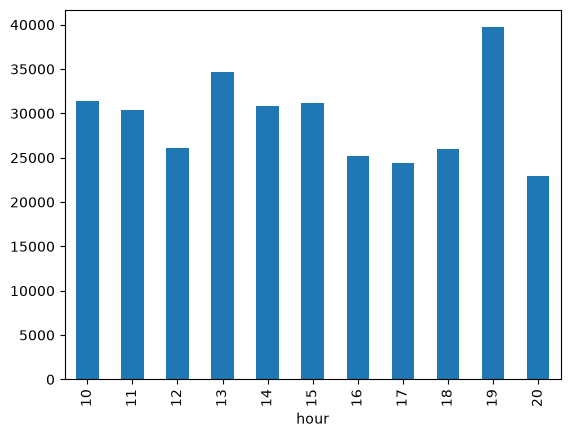

In [17]:
df['hour'] = pd.to_datetime(df['time'], format='%H:%M').dt.hour

hourly_sales = df.groupby('hour')['revenue'].sum()
print(hourly_sales)

hourly_sales.plot(kind='bar')
plt.show

**Sales by Hour:**
- 7 PM (hour 19) had the highest revenue (39,699.51), about 12.3% of the total .
- 1 PM (hour 13) was the second busiest hour (34,723.23).
- 8 PM (hour 20) had the lowest revenue (22,969.53).
- Sales peak in the evening and around lunch time .

# Key Insights 
- Food and beverages earned the highest revenue, and it is also the best rated product line (7.11).
- Branch C had the highest total revenue .
- January was the best month (116,291.87) and February the weakest  (97,219.37).
- Cash was the top payment method (34.7%), but all three methods are close.
- Members (50.8%) and female customers (52.0%) contributed slightly more revenue.
- Sales peak at 7 PM, with a second high at 1 PM.

# Recommendations
- Keep more staff and stock ready during 7 PM and 1 PM rush hours.
- Run promotions on Health and beauty, the lowest revenue product line.
- Offer member-only deals to keep the member customer coming back.

# Note
- The dataset covers only 3 months (Jan-Mar 2019), so these results show a short-term pattern, not a long-term ternd.